# 5106 — Portfolio Optimization Project (Group 1)

**Title:** Regularized Portfolio Construction with LASSO and Ridge  
**Course:** 5106  
**Group:** 1

This notebook implements the full workflow required by the project brief:

- Data cleaning for the *100 Portfolios Formed on Size × Operating Profitability (OP)* daily dataset  
- Rolling/sliding-window backtest (**126 trading-day lookback**):contentReference[oaicite:1]{index=1}  
- Portfolio strategies: Equally-Weighted (EW), Minimum-Variance (MinVar), LASSO, Ridge  
- Model selection via cross-validation with **TimeSeriesSplit**  
- Evaluation on **Validation-2** (2025-01-02 → 2025-06-30) and **Final Test** (2025-08-01 → 2025-08-30):contentReference[oaicite:2]{index=2}

Notes:
- Returns are in **percent** in the raw dataset → convert to **decimals**.:contentReference[oaicite:3]{index=3}  
- Short selling is allowed unless otherwise constrained.:contentReference[oaicite:5]{index=5}


In [1]:
# === Imports & configuration ===
import re
import numpy as np
import pandas as pd

from pathlib import Path
from typing import Tuple, Dict
from dataclasses import dataclass, field

import matplotlib.pyplot as plt

from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit

pd.set_option("display.max_columns", 120)
np.set_printoptions(suppress=True, precision=6)

# For reproducibility
RNG_SEED = 42
np.random.seed(RNG_SEED)


In [2]:
import pandas as pd
import numpy as np

# --- Set the path to your cleaned CSV file ---
DATA_PATH = '100_Portfolios_ME_OP_10x10_daily.csv'

df = pd.read_csv(DATA_PATH, index_col=False)
    
# Standardize column names
df = df.rename(columns={df.columns[0]: "date"})

# # Convert date column to datetime
df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d", errors="coerce")

df

/tmp/ipykernel_1234449/3814959084.py:7: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH, index_col=False)


,date,SMALL LoOP,ME1 OP2,ME1 OP3,ME1 OP4,ME1 OP5,ME1 OP6,ME1 OP7,ME1 OP8,ME1 OP9,SMALL HiOP,ME2 OP1,ME2 OP2,ME2 OP3,ME2 OP4,ME2 OP5,ME2 OP6,ME2 OP7,ME2 OP8,ME2 OP9,ME2 OP10,ME3 OP1,ME3 OP2,ME3 OP3,ME3 OP4,ME3 OP5,ME3 OP6,ME3 OP7,ME3 OP8,ME3 OP9,ME3 OP10,ME4 OP1,ME4 OP2,ME4 OP3,ME4 OP4,ME4 OP5,ME4 OP6,ME4 OP7,ME4 OP8,ME4 OP9,ME4 OP10,ME5 OP1,ME5 OP2,ME5 OP3,ME5 OP4,ME5 OP5,ME5 OP6,ME5 OP7,ME5 OP8,ME5 OP9,ME5 OP10,ME6 OP1,ME6 OP2,ME6 OP3,ME6 OP4,ME6 OP5,ME6 OP6,ME6 OP7,ME6 OP8,ME6 OP9,ME6 OP10,ME7 OP1,ME7 OP2,ME7 OP3,ME7 OP4,ME7 OP5,ME7 OP6,ME7 OP7,ME7 OP8,ME7 OP9,ME7 OP10,ME8 OP1,ME8 OP2,ME8 OP3,ME8 OP4,ME8 OP5,ME8 OP6,ME8 OP7,ME8 OP8,ME8 OP9,ME8 OP10,ME9 OP1,ME9 OP2,ME9 OP3,ME9 OP4,ME9 OP5,ME9 OP6,ME9 OP7,ME9 OP8,ME9 OP9,ME9 OP10,BIG LoOP,ME10 OP2,ME10 OP3,ME10 OP4,ME10 OP5,ME10 OP6,ME10 OP7,ME10 OP8,ME10 OP9,BIG HiOP
0,1963-07-01,-0.9,-0.65,-1.09,-1.2,-0.79,-0.36,-0.02,0.28,-0.92,-0.35,-0.31,-0.95,-1.35,-0.53,-0.97,-0.58,0.58,-0.33,-1.58,-0.5,-0.49,-0.76,-0.26,-1.01,-1.11,1.1,0.14,-0.7,-0.2,-1.3,-1.27,-0.7,-0.38,-1.64,-1.46,0.57,-0.63,-2.01,-1.4,-0.98,-0.82,-0.52,-0.39,-0.68,-1.65,-0.82,-0.83,-0.69,-0.48,-0.18,0.18,-0.01,-0.65,-0.61,0.41,-1.0,-0.55,-0.36,-0.67,-0.73,-0.34,-1.0,-0.06,-0.38,-0.03,-0.94,-0.38,-0.25,-0.55,-1.44,-0.47,-0.73,-0.13,-0.23,-0.55,-0.51,-0.68,-1.07,-0.24,-1.46,-2.17,-1.37,-0.75,-1.31,-0.58,-0.58,-0.29,-0.44,-0.57,-1.15,-0.91,-0.72,-0.58,-0.86,-0.56,-0.52,-0.65,-0.61,-0.56,-0.74
1,1963-07-02,0.26,0.18,0.24,-0.03,0.53,0.67,1.22,-0.12,-0.07,-0.11,0.5,0.38,1.9,0.79,1.27,1.79,1.1,0.67,0.74,-0.17,0.15,1.24,0.39,0.49,-0.23,0.08,0.29,0.82,-0.41,0.52,1.0,1.52,0.54,0.8,0.94,1.37,0.84,2.45,0.05,0.69,0.41,0.71,0.87,0.08,1.03,1.75,0.29,0.32,0.99,-0.36,0.12,0.59,0.74,-0.37,0.48,1.11,0.49,1.2,0.93,0.49,0.57,0.82,-0.13,0.72,0.46,0.9,0.54,0.36,0.21,1.01,0.7,-0.31,0.43,0.14,0.7,0.99,0.66,0.98,1.08,1.16,2.22,0.37,0.25,1.29,0.05,0.91,0.26,0.83,0.72,1.09,0.74,1.13,0.9,1.06,0.8,0.5,0.75,0.79,0.99,1.07
2,1963-07-03,0.71,0.79,-0.5,0.1,0.47,1.21,-0.06,0.34,-0.3,0.6,0.6,0.55,0.78,0.78,0.47,1.41,-2.0,0.96,0.65,0.52,-0.11,0.87,0.15,0.77,1.03,-0.3,-0.46,0.61,1.19,0.98,0.3,0.26,-0.28,0.35,0.34,0.41,1.27,-0.34,1.27,0.92,0.68,0.27,0.85,-0.26,0.48,1.04,-0.66,-0.11,0.81,0.89,0.89,0.82,0.34,0.67,0.56,-0.73,-0.09,0.97,0.2,1.46,0.7,0.14,0.62,0.86,0.46,0.79,0.26,0.32,0.93,0.03,-0.62,0.22,0.31,1.04,0.73,0.18,0.02,0.55,0.93,1.64,4.35,1.41,0.47,0.25,0.71,0.95,0.65,0.26,1.0,0.73,-0.24,0.13,0.77,1.28,0.83,0.22,0.47,1.02,0.36,0.3
3,1963-07-05,0.53,0.15,0.69,0.53,-0.07,-0.39,0.38,-0.14,0.03,0.51,1.07,0.01,1.18,0.92,0.0,1.04,-0.07,-0.04,0.23,1.05,0.74,-0.18,-0.42,0.46,-0.01,0.31,-0.02,0.2,0.56,1.06,0.9,1.19,-0.35,0.51,0.35,1.74,-0.34,3.74,0.42,-0.28,0.75,0.41,-0.37,0.65,0.44,0.84,0.38,1.42,0.43,0.48,1.63,0.59,0.01,-0.18,0.51,0.43,-0.62,0.01,-0.05,1.4,0.55,1.08,-0.05,-0.08,-0.27,0.46,0.32,0.74,0.12,1.07,0.79,0.95,0.01,0.33,-0.24,-0.05,-0.08,0.23,0.92,0.48,3.65,-0.12,0.56,0.12,0.76,0.33,0.48,0.35,0.1,0.31,0.28,0.8,0.18,0.97,0.19,0.04,0.72,0.08,0.38,0.76
4,1963-07-08,-0.39,-0.75,-0.29,-0.57,-1.49,-0.07,-0.91,-0.11,-1.13,0.07,-0.22,0.16,-0.77,0.46,0.55,-0.98,-0.4,0.51,-1.03,-0.47,-0.49,-0.52,0.38,-0.51,-0.52,-0.25,-0.3,-0.13,-0.57,-0.97,-0.92,-0.01,-0.47,-1.01,-1.09,-0.29,-0.79,-1.46,-1.3,-1.08,-0.64,-0.71,-0.22,-0.18,-1.05,-1.28,-0.45,-1.08,-1.16,-0.4,-0.61,0.18,-0.43,-0.86,-0.44,-0.46,-0.25,-0.8,-0.55,-0.09,-0.64,-0.76,-0.16,-0.23,-0.33,-0.01,-0.7,0.01,-0.34,0.01,-0.26,0.49,-0.03,-0.68,-0.25,-0.33,0.02,-0.63,-0.59,0.32,-1.01,-0.63,-0.9,-0.46,0.07,-0.42,-0.49,-0.3,-0.64,0.27,-0.22,-0.35,-0.64,-0.9,-0.73,-0.12,-0.26,-0.7,-0.63,-1.13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62420,2025-06-26,10

/tmp/ipykernel_1234449/1925397715.py:26: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method="ffill").dropna()


Cleaned data shape: (15603, 100) | Date range: 1963-07-01 → 2025-06-30
Validation-2 shapes: (354, 4) (354, 4)


,EW,MinVar,LASSO,Ridge
2024-01-02,-0.006326,-0.005697,-0.004340,-0.005941
2024-01-03,-0.022387,-0.024324,-0.022744,-0.024976
2024-01-04,233.843212,0.076945,3.716462,3.959187
2024-01-05,0.339300,0.007940,1.014794,0.355658
2024-01-08,0.338900,0.007954,0.993641,0.354692



== Validation-2 (Gross) ==


,Annualized Sharpe
EW,8.969621
LASSO,4.548692
Ridge,2.270494
MinVar,0.702855


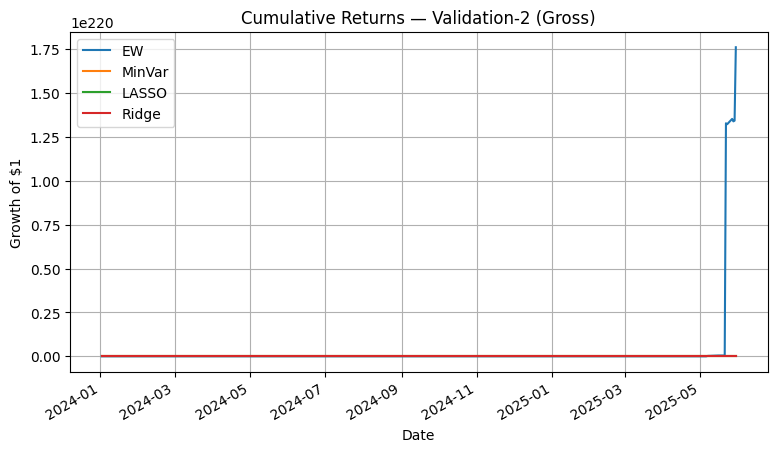


== Validation-2 (Net, after costs) ==


,Annualized Sharpe
EW,8.969621
LASSO,4.548673
Ridge,2.270331
MinVar,0.702346


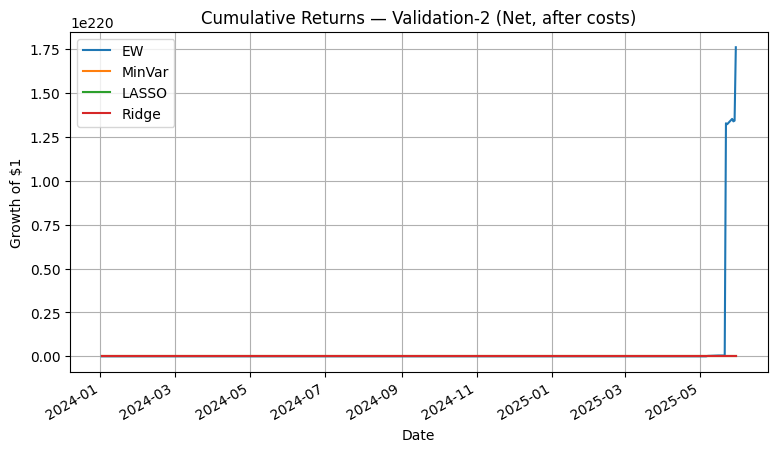

Final Test shapes: (20, 4) (20, 4)


,EW,MinVar,LASSO,Ridge
2025-06-02,0.311400,0.007094,0.942291,0.248901
2025-06-03,0.013046,0.014971,0.014608,0.014694
2025-06-04,295.360697,-0.494267,0.539260,0.780604
2025-06-05,294.486685,0.017422,-0.696417,-0.599832
2025-06-06,292.583052,0.156040,-0.536124,0.146175



== Final Test (Gross) ==


,Annualized Sharpe
EW,12.634072
LASSO,1.813550
Ridge,-1.499519
MinVar,-1.839651


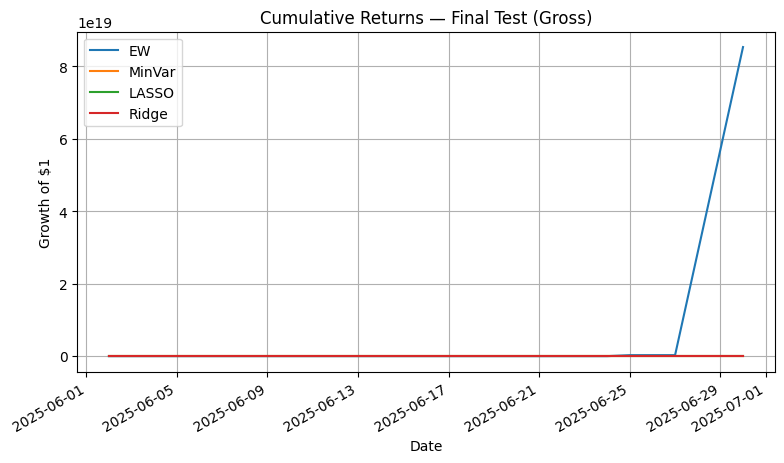


== Final Test (Net, after costs) ==


,Annualized Sharpe
EW,12.634072
LASSO,1.813538
Ridge,-1.500400
MinVar,-1.841068


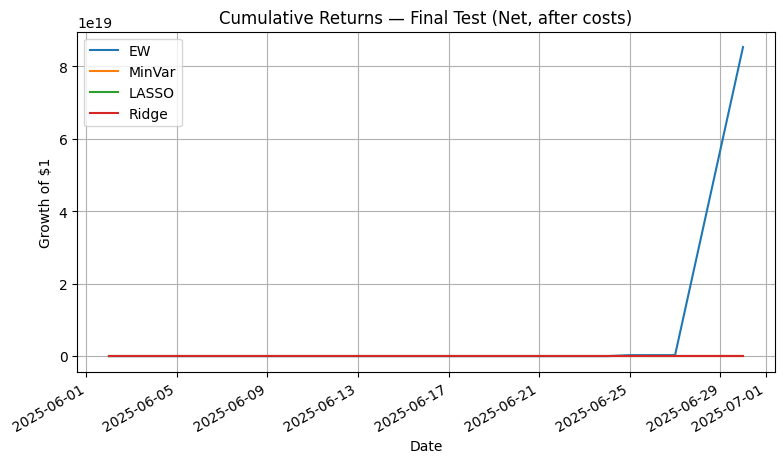


Mean daily turnover — Validation-2: {'EW': 0.0, 'MinVar': 0.07683764842337033, 'LASSO': 0.01196806615301425, 'Ridge': 0.03648208054331802}
Mean daily turnover — Final Test: {'EW': 0.0, 'MinVar': 0.06220661932292405, 'LASSO': 0.0021372570730834517, 'Ridge': 0.08621723866030524}


In [ ]:
# === Clean & prepare the CRSP "100 Portfolios ME x OP" daily data ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LassoCV, RidgeCV

plt.rcParams["figure.figsize"] = (9, 5)

# 0) Basic cleaning: dedupe, numeric, %→decimal
df = df.dropna(subset=["date"]).sort_values("date")
# Some WRDS exports can have duplicate same-day rows; keep the last
df = df[~df["date"].duplicated(keep="last")].set_index("date")

# coerce numerics, replace sentinel missing codes if present
df = df.replace({-99.99: np.nan, -999: np.nan})
df = df.apply(pd.to_numeric, errors="coerce")

# convert CRSP-style percent returns to decimals
df = df / 100.0

# drop any all-NaN columns (shouldn't happen but harmless)
df = df.loc[:, ~df.isna().all(0)]
# forward-fill tiny gaps within a column if any (daily factors can rarely miss a day)
df = df.fillna(method="ffill").dropna()

# enforce unique columns, just in case
if df.columns.duplicated().any():
    df = df.loc[:, ~df.columns.duplicated(keep="last")]

print("Cleaned data shape:", df.shape, "| Date range:", df.index.min().date(), "→", df.index.max().date())


# === Small utilities ===
RNG_SEED = 42
np.random.seed(RNG_SEED)
MAX_ITER = 30_000

def _safe_std(a, axis=0, ddof=1, eps=1e-12):
    s = np.asarray(a).std(axis=axis, ddof=ddof)
    return np.maximum(s, eps)

def ew_weights(p: int) -> np.ndarray:
    return np.ones(p) / p

def build_N(p: int) -> np.ndarray:
    """Difference basis so w = w_ew - N beta encodes relative tilts vs equal weight."""
    N = np.zeros((p, p-1))
    for j in range(p-1):
        N[j, j] = 1.0
        N[p-1, j] = -1.0
    return N

def long_only_simplex(w: np.ndarray) -> np.ndarray:
    w = np.clip(w, 0, None)
    s = w.sum()
    return w if s == 0 else (w / s)

def clamp_gross(w: np.ndarray, L: float = 1.5) -> np.ndarray:
    gross = np.abs(w).sum()
    return w if gross <= L else (w * (L / gross))

def sharpe_annual(r_daily: np.ndarray, trading_days: int = 252, rf_daily: float = 0.0) -> float:
    x = np.asarray(r_daily) - rf_daily
    mu, sd = x.mean(), x.std(ddof=1)
    return np.sqrt(trading_days) * mu / sd if sd > 0 else np.nan


# === Models: LASSO / Ridge on standardized window; MinVar with ridge shrink ===
def fit_lasso_ridge_standardized(R_window: np.ndarray,
                                 model: str,
                                 tscv: TimeSeriesSplit,
                                 lasso_alphas=None,
                                 ridge_alphas=None) -> np.ndarray:
    """
    Standardize X=R N and y=R w_ew within the window, fit without intercept,
    rescale coefficients back to original units so that w = w_ew - N beta_hat.
    """
    T, K = R_window.shape
    Nmat = build_N(K)
    w_ew = ew_weights(K)

    X = R_window @ Nmat           # (T, K-1)
    y = R_window @ w_ew           # (T,)

    Xm = X.mean(0, keepdims=True)
    Xs = _safe_std(X, axis=0, ddof=1)
    Xz = (X - Xm) / Xs

    ym = y.mean()
    ys = _safe_std(y, axis=0, ddof=1)
    yz = (y - ym) / ys

    if model == "lasso":
        if lasso_alphas is None:
            lasso_alphas = np.logspace(-5, 1, 50)
        est = LassoCV(alphas=lasso_alphas, cv=tscv, fit_intercept=False,
                      max_iter=MAX_ITER, random_state=RNG_SEED)
        est.fit(Xz, yz)
        beta_hat = (est.coef_ / Xs) * ys

    elif model == "ridge":
        if ridge_alphas is None:
            ridge_alphas = np.logspace(-3, 3, 50)
        est = RidgeCV(alphas=ridge_alphas, cv=tscv, fit_intercept=False)
        est.fit(Xz, yz)
        beta_hat = (est.coef_ / Xs) * ys

    else:
        raise ValueError("model must be 'lasso' or 'ridge'")

    # map back to portfolio weights
    w_hat = w_ew - (Nmat @ beta_hat)
    # sum-to-1 tidy
    return w_hat / w_hat.sum()


def minvar_ridge_weights(R_window: np.ndarray, lam: float = 1e-2) -> np.ndarray:
    """
    Penalized min-variance: argmin w' Σ w + lam ||w||^2 s.t. 1'w=1 (unconstrained sign).
    Closed-form via (Σ+lam I)^{-1} 1 normalized.
    """
    Sigma = np.cov(R_window, rowvar=False)
    K = Sigma.shape[0]
    A = Sigma + lam * np.eye(K)
    ones = np.ones(K)
    x = np.linalg.solve(A, ones)
    w = x / (ones @ x)
    return w


# === Trading costs helper ===
def returns_with_costs(R_panel: np.ndarray, W_panel: np.ndarray, cost_per_dollar: float = 0.0):
    """
    R_panel, W_panel have identical shapes (T x K). W at row t is *pre-trade* weight used for day t return.
    Turnover_t = ||w_t - w_{t-1}||_1, with w_{-1} = 0 vector.
    """
    r_gross = (W_panel * R_panel).sum(axis=1)
    dW = np.vstack([np.zeros_like(W_panel[0]), np.abs(W_panel[1:] - W_panel[:-1])])
    turnover = dW.sum(axis=1)
    r_net = r_gross - cost_per_dollar * turnover
    return r_gross, r_net, turnover


# === Core backtester ===
def backtest_strategies(
    returns: pd.DataFrame,
    start_date: str,
    end_date: str,
    lookback: int = 126,
    *,
    long_only: bool = False,
    gross_cap: float | None = 1.5,
    cost_per_dollar: float = 0.0002,   # e.g., 2 bps per $ turned
    ts_splits: int = 5,
):
    """
    Predict day t using a rolling window ending at t-1; realize P&L at t.
    Strategies: EW, MinVar, LASSO, Ridge. Weights are computed ONCE per day,
    stored, and then reused for costs — no second pass.
    """
    ret = returns.copy()
    if not isinstance(ret.index, pd.DatetimeIndex):
        ret.index = pd.to_datetime(ret.index)

    ret = ret.sort_index()
    # Defensive uniqueness (keeps function idempotent)
    if ret.index.has_duplicates:
        ret = ret[~ret.index.duplicated(keep="last")]
    if ret.columns.duplicated().any():
        ret = ret.loc[:, ~ret.columns.duplicated(keep="last")]

    start_ts, end_ts = pd.Timestamp(start_date), pd.Timestamp(end_date)
    # we need t-1 history and day t to realize; also skip very last row (no t+1)
    period_mask = (ret.index >= start_ts) & (ret.index <= end_ts)
    eval_dates = ret.index[period_mask]

    out_rows = []
    W_store = {k: {} for k in ("EW","MinVar","LASSO","Ridge")}

    for t in eval_dates:
        t_loc = ret.index.get_loc(t)
        if isinstance(t_loc, (slice, np.ndarray)):
            t_loc = np.where(ret.index == t)[0][0]

        # window: [t - lookback, t-1]
        win_start = t_loc - lookback
        win_end   = t_loc - 1
        if win_start < 0 or win_end < 0:
            continue  # insufficient history

        R_win = ret.iloc[win_start:win_end+1, :]
        # drop columns that are all-NaN within the window
        cols_ok = R_win.columns[~R_win.isna().all(0)]
        R_win = R_win[cols_ok]

        if R_win.shape[1] < 2:
            continue  # need at least 2 assets for the N-basis

        # realized day t vector (no leakage)
        r_t = ret.iloc[t_loc, :][cols_ok].values

        # Build CV splitter for this window
        tscv = TimeSeriesSplit(n_splits=min(ts_splits, max(2, len(R_win)//10)))

        # === Compute weights ONCE ===
        p = R_win.shape[1]
        w_ew    = ew_weights(p)
        w_minv  = minvar_ridge_weights(R_win.values, lam=1e-2)
        w_lasso = fit_lasso_ridge_standardized(R_win.values, model="lasso", tscv=tscv)
        w_ridge = fit_lasso_ridge_standardized(R_win.values, model="ridge", tscv=tscv)

        # Optional constraints
        def postprocess(w):
            if long_only:
                w = long_only_simplex(w)
            if gross_cap is not None:
                w = clamp_gross(w, L=gross_cap)
            s = w.sum()
            return w if np.isclose(s, 1.0) else (w / s)

        w_map = {
            "EW":     postprocess(w_ew),
            "MinVar": postprocess(w_minv),
            "LASSO":  postprocess(w_lasso),
            "Ridge":  postprocess(w_ridge),
        }

        # record one-step-ahead realized returns
        out_rows.append({
            "date": t,
            "EW":    float(w_map["EW"]    @ r_t),
            "MinVar":float(w_map["MinVar"]@ r_t),
            "LASSO": float(w_map["LASSO"] @ r_t),
            "Ridge": float(w_map["Ridge"] @ r_t),
        })

        # store weights (indexed only by the assets that existed in this window)
        for k in w_map:
            W_store[k][t] = pd.Series(w_map[k], index=cols_ok)

    if not out_rows:
        return pd.DataFrame(), pd.DataFrame(), {}

    oos_gross = pd.DataFrame(out_rows).set_index("date").sort_index()

    # === Trading costs: strictly align to each strategy's weight grid ===
    oos_net = {}
    turnovers = {}
    for k in ("EW","MinVar","LASSO","Ridge"):
        # Build W panel: rows = dates we actually traded this strategy; cols = union of seen assets
        W_df = pd.DataFrame.from_dict(W_store[k], orient="index").sort_index()
        # Align returns to exactly that grid
        R_df = returns.reindex(index=W_df.index, columns=W_df.columns)

        # Fill NaNs safely: missing weights → 0 exposure; missing returns → 0 contribution
        W_df = W_df.fillna(0.0)
        R_df = R_df.fillna(0.0)

        # Compute gross & net using *these* dates only
        r_g, r_n, turn = returns_with_costs(R_df.values, W_df.values, cost_per_dollar=cost_per_dollar)
        oos_net[k] = pd.Series(r_n, index=W_df.index)
        turnovers[k] = pd.Series(turn, index=W_df.index)

    oos_net = pd.DataFrame(oos_net).sort_index()

    # Align gross & net to common intersection (some strategies might have fewer days)
    common_idx = oos_gross.index.intersection(oos_net.index)
    oos_gross = oos_gross.reindex(common_idx)
    oos_net   = oos_net.reindex(common_idx)

    return oos_gross, oos_net, turnovers


# === Evaluation helper ===
def evaluate_block(oos: pd.DataFrame, title: str):
    if oos.empty:
        print(f"[{title}] No OOS observations.")
        return pd.Series(dtype=float)

    s = {c: sharpe_annual(oos[c].values) for c in oos.columns}
    sr = pd.Series(s, name="Annualized Sharpe").sort_values(ascending=False)
    print(f"\n== {title} ==")
    display(sr.to_frame())

    # cum growth
    (1 + oos.fillna(0)).cumprod().plot()
    plt.title(f"Cumulative Returns — {title}")
    plt.xlabel("Date"); plt.ylabel("Growth of $1"); plt.grid(True); plt.show()
    return sr


# === Run the two required evaluation windows ===
LOOKBACK = 126

VAL2_START, VAL2_END = "2024-01-02", "2025-05-30"
TEST_START,  TEST_END = "2025-06-01", "2025-06-30"

val2_gross, val2_net, val2_turn = backtest_strategies(
    df, VAL2_START, VAL2_END, lookback=LOOKBACK,
    long_only=False, gross_cap=1.5, cost_per_dollar=0.0002, ts_splits=5
)
print("Validation-2 shapes:", val2_gross.shape, val2_net.shape)
print(val2_gross.head())

sr_val2_g = evaluate_block(val2_gross, "Validation-2 (Gross)")
sr_val2_n = evaluate_block(val2_net,   "Validation-2 (Net, after costs)")

test_gross, test_net, test_turn = backtest_strategies(
    df, TEST_START, TEST_END, lookback=LOOKBACK,
    long_only=False, gross_cap=1.5, cost_per_dollar=0.0002, ts_splits=5
)
print("Final Test shapes:", test_gross.shape, test_net.shape)
print(test_gross.head())

sr_test_g = evaluate_block(test_gross, "Final Test (Gross)")
sr_test_n = evaluate_block(test_net,   "Final Test (Net, after costs)")

# (Optional) peek at average daily turnover (helpful sanity check on costs)
if val2_turn:
    avg_turn_val2 = {k: float(v.mean()) for k, v in val2_turn.items()}
    print("\nMean daily turnover — Validation-2:", avg_turn_val2)
if test_turn:
    avg_turn_test = {k: float(v.mean()) for k, v in test_turn.items()}
    print("Mean daily turnover — Final Test:", avg_turn_test)
